# Pivot Calibration
Luke Doladille, Oct. 19, 2025

## Introduction on pivot calibration

A transformation from a point $P_{t}$ in the pointer's LCS (marker coordinate system) to its corresponding point $P_{p}$ in the camera's coordinate system is given by: $$P_{p} = R_i \cdot P_{t} + t_i $$

- $R_i$ is the $3\text{x}3$ rotation matrix;
- $t_i$ is the $3\text{x}1$ translation vector, ie the coordinates of the origin of the LCS in the camera's coordinate system. 

These two objects are combined into one $3\text{x}4$ matrix, a compact way to represent a rigid body transformation. 

Below is a picture explaining the principles and notations of pivot calibration. 

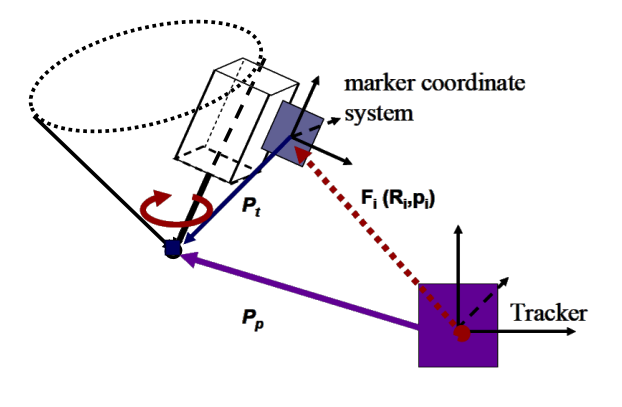

Image source: Course content from BME8113-Advanced Intraoperative Imaging

## Task 1: Compute the coordinate of the tool tip in the pointer’s local coordinate system

The objective of this task is to find $P_t$, the position of the pointer's tip in the pointer's local coordinate system (LCS). 

The pivot calibration's principle is that the operator rotates the pointer in a circular motion while maintaining the pointer's tip into place. This means $P_p$ and $P_t$ are constant. 

For each measurement, thanks to a tracker API, we are given $R_i$ and $t_i$ in the form of a $3\text{x}4$ matrix. 

We have : $P_p = R_i \cdot P_t + t_i$

Since both $P_p$ and $P_t$ are unknown but constant, we can rearrange the equation to group the unknowns on one side and the knowns on the other:$$R_i \cdot P_t - P_p = -t_i$$

This is a system of 3 linear equations for each measurement. With $n$ measurements, we can stack them all to form a large, overdetermined system of linear equations of the form $A\mathbf{x} = \mathbf{b}$. 

We note: $$\mathbf{x} = \begin{pmatrix} P_t \\ P_p \end{pmatrix}$$

This is a 6×1 vector. 

The matrix $A$ and vector $\mathbf{b}$ are constructed by stacking the components from each measurement $i=1...N$:$$A = \begin{pmatrix} R_1 & -I \\ R_2 & -I \\ \vdots & \vdots \\ R_N & -I \end{pmatrix}, \quad
\mathbf{b} = \begin{pmatrix} -t_1 \\ -t_2 \\ \vdots \\ -t_N \end{pmatrix}$$where $I$ is the $3 \times 3$ identity matrix. The resulting matrix $A$ will be $(3N \times 6)$ and vector $\mathbf{b}$ will be $(3N \times 1)$.

We find the best-fit solution using the least-squares method:$$\mathbf{x} = (A^T A)^{-1} A^T \mathbf{b}$$

This gives us the 6×1 vector x, from which we extract $P_t$ as the first 3 components.

## Task 2: Calculation of Root Mean Square Error (RMSE)

The Root Mean Square Error (RMSE) is computed to quantify the quality and consistency of the pivot calibration. This metric represents the average residual error between the predicted pivot point position for each measurement and the single, best-fit pivot point $P_p$ derived from the complete dataset.

The least-squares solution provides the optimal coordinates for the pointer's tip in the LCS $P_t$, and the pointer's tip in the camera's coordinate system $P_p$.

To calculate the RMSE, the pivot point's position in the camera frame is first re-calculated for each individual measurement $i$, using the known local tool tip vector $P_t$ and the $i$-th transformation matrix $[R_i | t_i]$. This predicted position is denoted $\hat{P}_{p, i}$:

$$\hat{P}_{p, i} = R_i \cdot P_t + t_i$$

The residual error $e_i$ for each measurement is the Euclidean distance between this predicted position $\hat{P}_{p, i}$ and the globally optimized pivot position $P_p$:

$$e_i = \| \hat{P}_{p, i} - P_p \|$$

Finally, the RMSE is calculated as the square root of the mean of these squared residual errors over all $N$ measurements:

$$\text{RMSE} = \sqrt{\frac{1}{N} \sum_{i=1}^{N} e_i^2} = \sqrt{\frac{1}{N} \sum_{i=1}^{N} \| \hat{P}_{p, i} - P_p \|^2}$$

A low RMSE (typically sub-millimeter) indicates high stability of the pivot point during data acquisition and, consequently, a high-quality and reliable calibration.

## Implementation in Python

In [ ]:
import numpy as np
import ast

def solve_pivot_calibration(filename="Tpointer2Cam.txt"):
    
    R_matrices = []
    t_vectors = []
    A_list = []
    b_list = []
    I_neg = -np.eye(3) # The -I block

    print(f"Reading data from '{filename}'...")

    with open(filename, 'r') as f:
        for line in f:
            line = line.strip()
            if not line: # Skip empty lines
                continue
            
            # Safely evaluate the string "[[-0.9...], ...]"
            T_i = np.array(ast.literal_eval(line))
            
            if T_i.shape != (3, 4):
                print(f"Warning: Skipping malformed line. Shape was {T_i.shape}")
                continue
                
            R_i = T_i[:, :3]
            t_i = T_i[:, 3]
            
            # Store for RMSE calculation
            R_matrices.append(R_i)
            t_vectors.append(t_i)
            
            # Build the blocks for the Ax = b system
            # [R_i  -I] * [P_t] = [-t_i]
            #            [P_p]
            A_list.append(np.hstack([R_i, I_neg]))
            b_list.append(-t_i)

    if not A_list:
        print("Error: No valid data was read from the file.")
        return

    # --- Task 1: Solve for Tip Coordinate ---
    
    A = np.vstack(A_list)
    b = np.concatenate(b_list)
    num_measurements = len(R_matrices)

    print(f"Data loaded. Found {num_measurements} measurements.")

    # Solve the overdetermined system Ax = b
    solution, residuals, rank, s = np.linalg.lstsq(A, b, rcond=None)
    
    P_t = solution[0:3] # First 3 elements are P_t (local tip)
    P_p = solution[3:6] # Last 3 elements are P_p (pivot in cam)
    
    print("\n--- Task 1 Result ---")
    print(f"Computed tool tip coordinate in pointer LCS (P_t):")
    print(f"  x = {P_t[0]:.4f}")
    print(f"  y = {P_t[1]:.4f}")
    print(f"  z = {P_t[2]:.4f}")

    # --- Task 2: Compute RMSE ---
    
    sum_squared_errors = 0
    for i in range(num_measurements):
        R_i = R_matrices[i]
        t_i = t_vectors[i]
        
        # Predict pivot point in camera space using this measurement's
        # transform and our calculated P_t
        # P_p_hat_i = R_i * P_t + t_i
        P_p_predicted_i = R_i @ P_t + t_i
        
        # Calculate the error: distance between this prediction
        # and the single best-fit pivot point (P_p)
        # e_i = || P_p_hat_i - P_p ||
        e_i_vec = P_p_predicted_i - P_p
        squared_error = np.dot(e_i_vec, e_i_vec) # ||e_i_vec||^2
        sum_squared_errors += squared_error
    
    mean_squared_error = sum_squared_errors / num_measurements
    rmse = np.sqrt(mean_squared_error)
    
    print("\n--- Task 2 Result ---")
    print(f"Root Mean Square Error (RMSE) of calibration: {rmse:.4f} mm")
    
solve_pivot_calibration("Tpointer2Cam.txt")

Reading data from 'Tpointer2Cam.txt'...
Data loaded. Found 259 measurements.

--- Task 1 Result ---
Computed tool tip coordinate in pointer LCS (P_t):
  x = 208.4182
  y = -0.6433
  z = -33.1314

--- Task 2 Result ---
Root Mean Square Error (RMSE) of calibration: 0.4482 mm
